# Exploración de datos — Bank Marketing (UCI)

Este notebook conserva **únicamente la exploración y las decisiones de limpieza** del proyecto.
El preprocesamiento, el entrenamiento, la evaluación y el registro en MLflow se migraron al script
[`train.py`](../train.py), que se ejecuta desde la línea de comandos (ver `README.md`).

**Problema:** predecir si un cliente suscribirá un depósito a plazo (`y`) — clasificación binaria desbalanceada (~11.7 % positivos).

> Fuente: Moro, S., Cortez, P. & Rita, P. (2014). *A Data-Driven Approach to Predict the Success of Bank Telemarketing*. UCI Machine Learning Repository.

### 0. Configuración del entorno
Importamos librerías y fijamos una semilla global para que los resultados sean reproducibles.

In [1]:
# --- Librerías de manipulación de datos y visualización ---
import warnings
warnings.filterwarnings("ignore")          # silenciamos avisos no críticos
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Rutas relativas a la carpeta notebooks/
DATA_PATH = Path("../data/bank-full.csv")
FIG_DIR = Path("figuras"); FIG_DIR.mkdir(exist_ok=True)

---
## Paso 1. Carga y descripción del dataset
El archivo `bank-full.csv` usa `;` como separador. Lo cargamos con pandas.

In [2]:
# Cargamos el CSV indicando el separador ';'
df_raw = pd.read_csv(DATA_PATH, sep=";")

# Dimensiones del dataset
print(f"Registros: {df_raw.shape[0]:,} | Variables: {df_raw.shape[1]}")
df_raw.head()

Registros: 45,211 | Variables: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Tipos de datos, conteo de no nulos y uso de memoria
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


### Diccionario de variables
| # | Variable | Tipo | Significado |
|---|----------|------|-------------|
| 1 | `age` | numérica (int) | Edad del cliente |
| 2 | `job` | categórica | Tipo de empleo (admin., blue-collar, technician, …, unknown) |
| 3 | `marital` | categórica | Estado civil (married, single, divorced; *divorced* incluye viudos) |
| 4 | `education` | categórica | Nivel educativo (primary, secondary, tertiary, unknown) |
| 5 | `default` | binaria | ¿Tiene crédito en mora? |
| 6 | `balance` | numérica (int) | Saldo medio anual en euros (puede ser negativo) |
| 7 | `housing` | binaria | ¿Tiene préstamo hipotecario? |
| 8 | `loan` | binaria | ¿Tiene préstamo personal? |
| 9 | `contact` | categórica | Medio de contacto (cellular, telephone, unknown) |
| 10 | `day` | numérica (int) | Día del mes del último contacto |
| 11 | `month` | categórica | Mes del último contacto (jan … dec) |
| 12 | `duration` | numérica (int) | Duración del último contacto en segundos |
| 13 | `campaign` | numérica (int) | Nº de contactos en esta campaña (incluye el último) |
| 14 | `pdays` | numérica (int) | Días desde el último contacto de una campaña anterior (-1 = nunca contactado) |
| 15 | `previous` | numérica (int) | Nº de contactos en campañas anteriores |
| 16 | `poutcome` | categórica | Resultado de la campaña anterior (success, failure, other, unknown) |
| 17 | **`y`** | **binaria (objetivo)** | **¿El cliente suscribió un depósito a plazo?** |

**Resumen de estructura:** 45,211 registros, 16 variables predictoras (7 numéricas y 9 categóricas/binarias) y 1 variable objetivo binaria.

In [4]:
# Separamos los nombres de columnas por tipo para usarlos más adelante
num_cols = df_raw.select_dtypes(include="number").columns.tolist()
cat_cols = df_raw.select_dtypes(include="object").columns.drop("y").tolist()
print("Numéricas  :", num_cols)
print("Categóricas:", cat_cols)

Numéricas  : ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


---
## Paso 2. Análisis exploratorio de datos (EDA)
### 2.1 Estadísticas descriptivas

In [5]:
# Estadísticas de las variables numéricas (incluimos percentiles extremos para detectar colas)
df_raw[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
age,45211.0,40.94,10.62,18.0,23.0,33.0,39.0,48.0,71.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,-627.0,72.0,448.0,1428.0,13164.9,102127.0
day,45211.0,15.81,8.32,1.0,2.0,8.0,16.0,21.0,31.0,31.0
duration,45211.0,258.16,257.53,0.0,11.0,103.0,180.0,319.0,1269.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,1.0,2.0,3.0,16.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,-1.0,370.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,0.0,8.9,275.0


In [6]:
# Estadísticas de las variables categóricas: nº de categorías, la más frecuente y su frecuencia
df_raw[cat_cols + ["y"]].describe().T

,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


### 2.2 Variable objetivo

         n     %
y               
no   39922  88.3
yes   5289  11.7


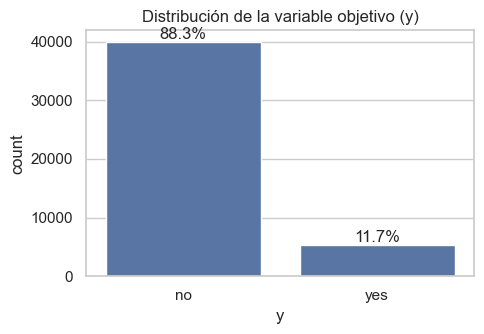

In [7]:
# Distribución de la variable objetivo: ¿está balanceada?
dist_y = df_raw["y"].value_counts()
print(pd.concat([dist_y, (dist_y / len(df_raw) * 100).round(2)], axis=1, keys=["n", "%"]))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df_raw, x="y", ax=ax)
for p in ax.patches:  # anotamos el porcentaje sobre cada barra
    ax.annotate(f"{p.get_height()/len(df_raw):.1%}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Distribución de la variable objetivo (y)")
plt.tight_layout(); plt.savefig(FIG_DIR / "dist_objetivo.png", dpi=110); plt.show()

**Observación:** solo ~11.7 % de los clientes suscribe. El dataset está **desbalanceado** (≈ 7.5 : 1), por lo que la
*accuracy* será engañosa: un modelo que siempre diga "no" acertaría el 88 %. Esto condiciona la elección de métricas (Paso 5).

### 2.3 Distribución de variables numéricas

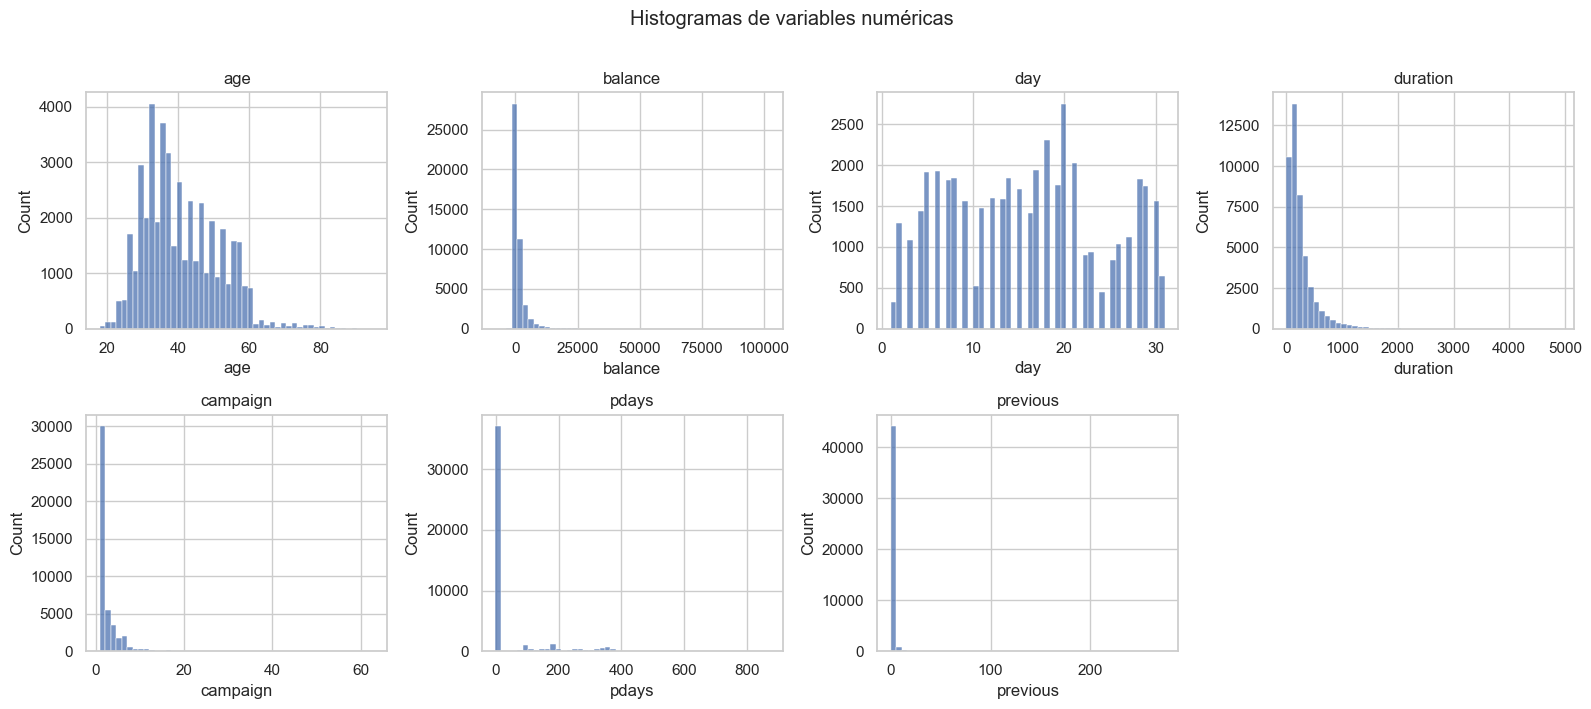

In [8]:
# Histogramas de todas las variables numéricas
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df_raw[col], bins=50, ax=ax, kde=False)
    ax.set_title(col)
axes.flat[-1].axis("off")  # sobra un panel (7 variables en 8 huecos)
plt.suptitle("Histogramas de variables numéricas", y=1.01)
plt.tight_layout(); plt.savefig(FIG_DIR / "hist_numericas.png", dpi=110); plt.show()

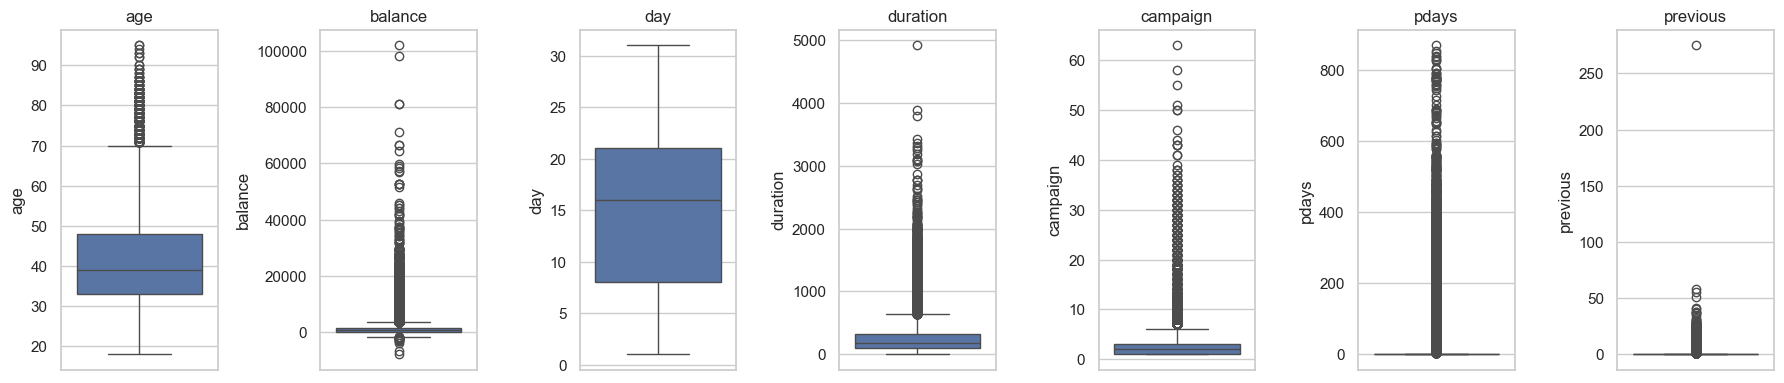

In [9]:
# Boxplots para visualizar valores atípicos
fig, axes = plt.subplots(1, 7, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_raw[col], ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.savefig(FIG_DIR / "boxplots.png", dpi=110); plt.show()

**Observaciones:**
- `age` es aproximadamente normal con cola derecha (18–95 años, mediana 39).
- `balance`, `duration`, `campaign`, `pdays` y `previous` tienen **fuerte asimetría positiva** y colas largas (p. ej. `balance` máx. 102,127 € frente a p99 ≈ 13,000 €; `campaign` máx. 63 frente a p99 = 16).
- `pdays` vale -1 en ~82 % de los registros: es un **código especial** ("nunca contactado"), no un número real de días.

### 2.4 Distribución de variables categóricas y tasa de éxito por categoría

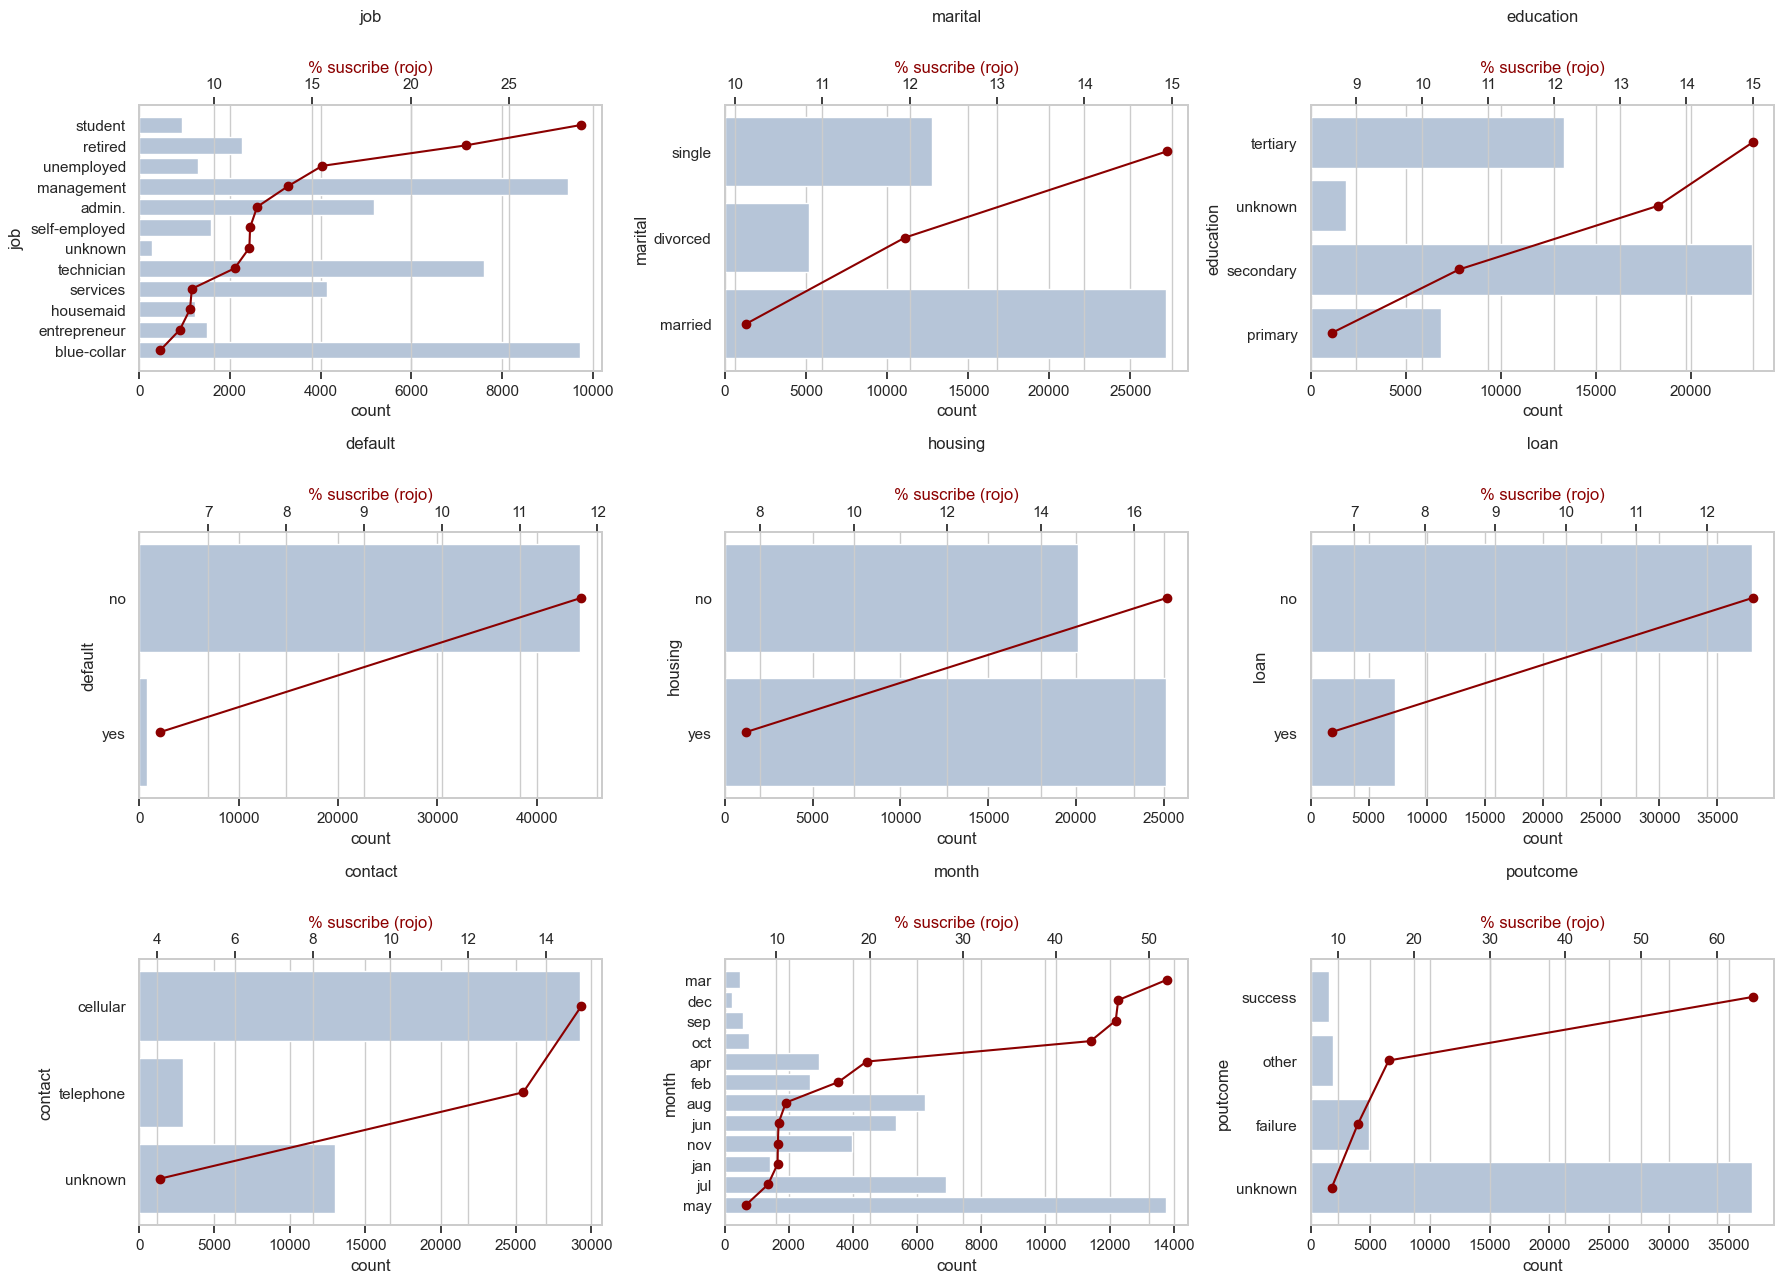

In [10]:
# Para cada variable categórica: frecuencia (barras) y tasa de suscripción (%) por categoría
y_bin = (df_raw["y"] == "yes").astype(int)
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, col in zip(axes.flat, cat_cols):
    tasa = y_bin.groupby(df_raw[col]).mean().sort_values(ascending=False) * 100
    orden = tasa.index
    sns.countplot(data=df_raw, y=col, order=orden, ax=ax, color="lightsteelblue")
    ax2 = ax.twiny()  # segundo eje para la tasa de éxito
    ax2.plot(tasa.values, range(len(tasa)), "o-", color="darkred")
    ax2.set_xlabel("% suscribe (rojo)", color="darkred")
    ax.set_title(col, pad=28)
plt.tight_layout(); plt.savefig(FIG_DIR / "categoricas_tasa.png", dpi=110); plt.show()

**Observaciones:**
- `poutcome = success` tiene una tasa de suscripción de ~65 %: haber aceptado en una campaña anterior es el indicador individual más fuerte.
- Estudiantes (`student`) y jubilados (`retired`) convierten mucho más (~29 % y ~23 %) que `blue-collar` (~7 %).
- Meses con pocas llamadas (`mar`, `sep`, `oct`, `dec`) tienen tasas altísimas (>40 %); `may` concentra el mayor volumen y la menor tasa.
- Quienes tienen hipoteca (`housing = yes`) o préstamo personal (`loan = yes`) suscriben menos.
- El valor `unknown` aparece en `job`, `education`, `contact` y `poutcome` (se trata en el Paso 3).

### 2.5 Relaciones entre variables numéricas y con el objetivo

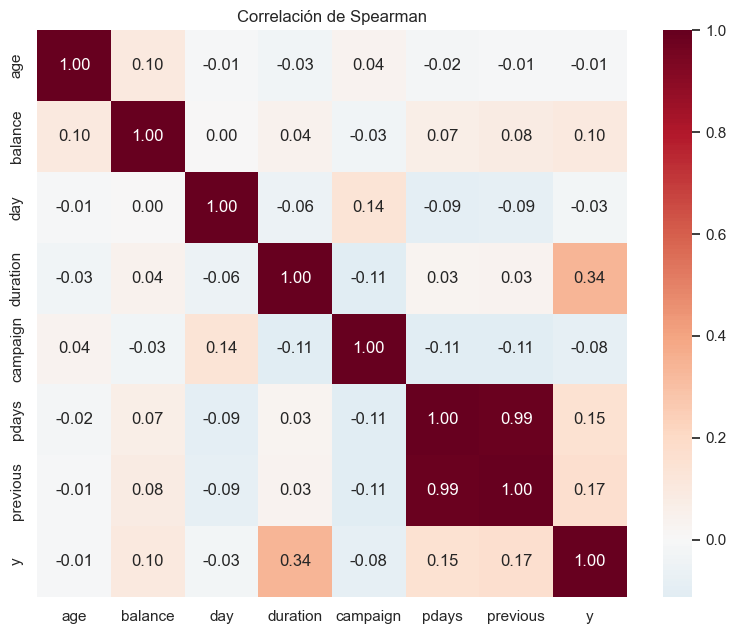

In [11]:
# Matriz de correlación de Spearman (robusta a asimetría y outliers), incluyendo el objetivo binario
corr = df_raw[num_cols].assign(y=y_bin).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlación de Spearman")
plt.tight_layout(); plt.savefig(FIG_DIR / "correlacion.png", dpi=110); plt.show()

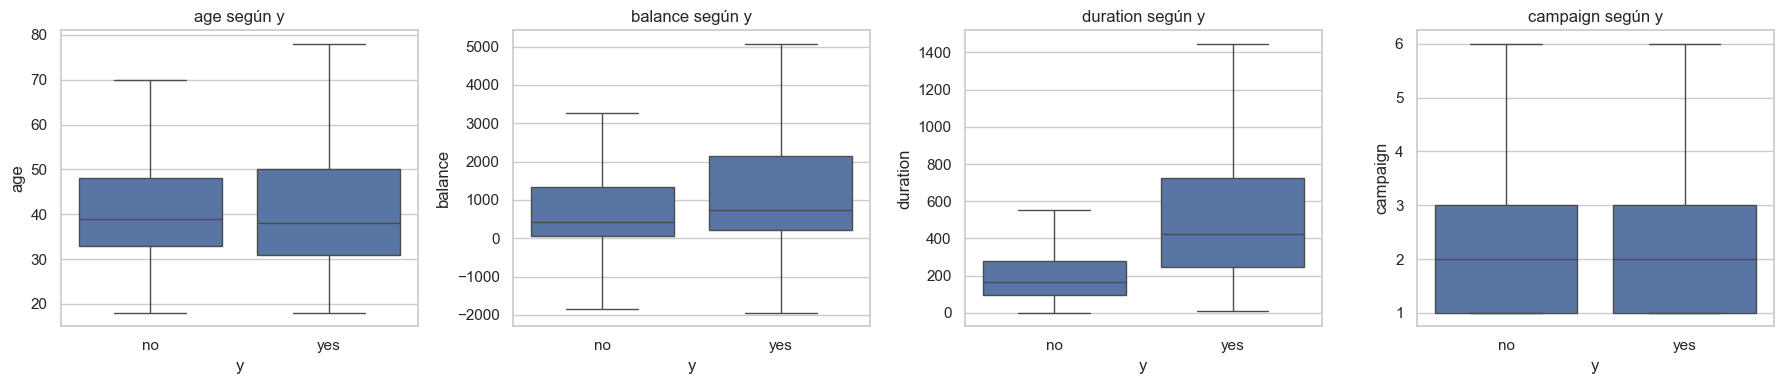

y,no,yes
age,39.0,38.0
balance,417.0,733.0
day,16.0,15.0
duration,164.0,426.0
campaign,2.0,2.0
pdays,-1.0,-1.0
previous,0.0,0.0


In [12]:
# Comparamos la distribución de algunas variables numéricas según el objetivo
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["age", "balance", "duration", "campaign"]):
    sns.boxplot(data=df_raw, x="y", y=col, ax=ax, showfliers=False)  # sin outliers para ver el cuerpo
    ax.set_title(f"{col} según y")
plt.tight_layout(); plt.savefig(FIG_DIR / "numericas_vs_y.png", dpi=110); plt.show()

# Medianas por clase como resumen numérico
df_raw.groupby("y")[num_cols].median().T

**Observaciones:**
- `pdays` y `previous` están muy correlacionadas entre sí (ρ ≈ 0.99 en Spearman) porque ambas codifican "¿fue contactado antes?".
- `duration` es la variable más asociada con `y` (ρ ≈ 0.34): las llamadas exitosas duran mucho más (mediana ~426 s vs ~164 s).
  **Sin embargo, `duration` solo se conoce *después* de la llamada**, por lo que usarla para decidir a quién llamar sería *fuga de información* (data leakage). La documentación original del dataset lo advierte explícitamente.
- Más contactos en la campaña (`campaign`) se asocian a menor éxito: insistir no parece ayudar.
- `balance` es ligeramente mayor entre quienes suscriben.

---
## Paso 3. Limpieza de datos
Trabajamos sobre una copia para conservar los datos originales intactos. Cada sub-paso registra la decisión tomada en
un *log* de limpieza que resume lo que implementa la función `clean_data()` de `train.py`.

In [13]:
df = df_raw.copy()
log_limpieza = []   # bitácora de decisiones de limpieza

### 3.1 Valores faltantes

In [14]:
# Nulos explícitos (NaN)
nulos = df.isna().sum()
print("Total de NaN:", nulos.sum())

# Nulos 'implícitos': la categoría 'unknown'
unknown = (df[cat_cols] == "unknown").sum()
unknown = unknown[unknown > 0]
pd.DataFrame({"n_unknown": unknown, "%": (unknown / len(df) * 100).round(2)})

Total de NaN: 0


,n_unknown,%
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


**Decisión:**
- No hay `NaN` explícitos.
- Los `unknown` **se conservan como una categoría propia** en lugar de imputarlos o eliminar filas:
  - En `poutcome` (81.7 %) `unknown` significa en realidad "no hubo campaña anterior": es información, no un faltante.
  - En `contact` (28.8 %) eliminar filas sesgaría la muestra (se concentran en mayo-junio de 2008).
  - En `job` (0.6 %) y `education` (4.1 %) la proporción es pequeña; imputar con la moda introduciría ruido y el One-Hot Encoding ya maneja la categoría.

In [15]:
log_limpieza.append("Faltantes: 0 NaN. 'unknown' en job/education/contact/poutcome se conserva como categoría propia.")

### 3.2 Duplicados

In [16]:
n_dup = df.duplicated().sum()
print("Filas duplicadas exactas:", n_dup)
df = df.drop_duplicates().reset_index(drop=True)   # no elimina nada si n_dup == 0, pero deja el paso explícito
log_limpieza.append(f"Duplicados: {n_dup} filas duplicadas exactas -> eliminadas (si las hubiera).")

Filas duplicadas exactas: 0


**Decisión:** no hay duplicados exactos. Se deja el paso en el código para que el flujo sea robusto si los datos cambian.

### 3.3 Tipos de datos incorrectos o mejorables

In [17]:
# 1) Variables binarias 'yes'/'no' -> 0/1 (incluida la variable objetivo)
bin_cols = ["default", "housing", "loan", "y"]
for c in bin_cols:
    assert set(df[c].unique()) <= {"yes", "no"}, f"Valores inesperados en {c}"
    df[c] = (df[c] == "yes").astype(int)

# 2) pdays = -1 es un código, no un número. Creamos un indicador explícito
#    y sustituimos -1 por 0 para que la escala numérica tenga sentido ("0 días" solo aplica a contactados).
df["contactado_antes"] = (df["pdays"] != -1).astype(int)
df.loc[df["pdays"] == -1, "pdays"] = 0

# 3) Las categóricas restantes pasan a tipo 'category' (más memoria-eficiente y semánticamente correcto)
cat_restantes = ["job", "marital", "education", "contact", "month", "poutcome"]
df[cat_restantes] = df[cat_restantes].astype("category")

log_limpieza += [
    "Tipos: default/housing/loan/y convertidos de 'yes/no' a 0/1.",
    "Tipos: pdays=-1 (no contactado) -> nueva variable binaria 'contactado_antes' y pdays=-1 reemplazado por 0.",
    "Tipos: job/marital/education/contact/month/poutcome convertidas a 'category'.",
]
df.dtypes

age                    int64
job                 category
marital             category
education           category
default                int64
balance                int64
housing                int64
loan                   int64
contact             category
day                    int64
month               category
duration               int64
campaign               int64
pdays                  int64
previous               int64
poutcome            category
y                      int64
contactado_antes       int64
dtype: object

### 3.4 Valores atípicos (outliers)

In [18]:
# Detectamos outliers con la regla de Tukey (1.5 * IQR) en cada numérica
def resumen_outliers(data, cols):
    filas = []
    for c in cols:
        q1, q3 = data[c].quantile([.25, .75])
        iqr = q3 - q1
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = ((data[c] < li) | (data[c] > ls)).sum()
        filas.append({"variable": c, "lim_inf": li, "lim_sup": ls, "n_outliers": n,
                      "%": round(n / len(data) * 100, 2), "min": data[c].min(), "max": data[c].max()})
    return pd.DataFrame(filas).set_index("variable")

resumen_outliers(df, ["age", "balance", "duration", "campaign", "previous"])

,lim_inf,lim_sup,n_outliers,%,min,max
variable,,,,,,
age,10.5,70.5,487,1.08,18,95
balance,-1962.0,3462.0,4729,10.46,-8019,102127
duration,-221.0,643.0,3235,7.16,0,4918
campaign,-2.0,6.0,3064,6.78,1,63
previous,0.0,0.0,8257,18.26,0,275


**Decisión:**
- Los valores extremos son **plausibles** (clientes con saldos altos, personas de 90 años, un cliente contactado 63 veces), no errores de captura. **No se eliminan filas**: perderíamos hasta un 10 % de los datos y justamente casos informativos.
- Como el modelo base es lineal (regresión logística) y es sensible a valores extremos, aplicamos **winsorización (recorte) al percentil 1–99** en `balance`, `campaign` y `previous`.
- **Los límites se calculan solo con el conjunto de entrenamiento** (función `winsorize()` de `train.py`) y luego se aplican al de prueba, para no filtrar información del test.
- Única corrección de rango: se verifica que no haya edades < 18 ni valores negativos en conteos.

In [19]:
# Comprobaciones de consistencia de rango (errores de captura)
assert df["age"].between(18, 100).all(), "Edades fuera de rango"
assert (df[["campaign", "previous", "duration", "pdays"]] >= 0).all().all(), "Conteos negativos"
assert df["day"].between(1, 31).all(), "Día del mes inválido"
print("Validaciones de rango superadas ✔")
log_limpieza.append("Outliers: sin errores de rango; se conservan filas. Winsorización p1-p99 en balance/campaign/previous con límites del train.")

Validaciones de rango superadas ✔


### 3.5 Eliminación de variables con fuga de información

In [20]:
# 'duration' solo se conoce al terminar la llamada -> no es usable para predecir antes de llamar
df = df.drop(columns=["duration"])
log_limpieza.append("Leakage: se elimina 'duration' (solo conocida después de la llamada).")

print(f"Dataset limpio: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print("\n".join(f"- {l}" for l in log_limpieza))

Dataset limpio: 45,211 filas x 17 columnas
- Faltantes: 0 NaN. 'unknown' en job/education/contact/poutcome se conserva como categoría propia.
- Duplicados: 0 filas duplicadas exactas -> eliminadas (si las hubiera).
- Tipos: default/housing/loan/y convertidos de 'yes/no' a 0/1.
- Tipos: pdays=-1 (no contactado) -> nueva variable binaria 'contactado_antes' y pdays=-1 reemplazado por 0.
- Tipos: job/marital/education/contact/month/poutcome convertidas a 'category'.
- Outliers: sin errores de rango; se conservan filas. Winsorización p1-p99 en balance/campaign/previous con límites del train.
- Leakage: se elimina 'duration' (solo conocida después de la llamada).


---
## Del notebook al script
Las decisiones anteriores se trasladaron a funciones de `train.py`:

| Decisión del EDA | Función en `train.py` |
|---|---|
| Lectura del CSV (`sep=';'`) | `load_data()` |
| `yes/no → 1/0`, indicador `contactado_antes`, `unknown` como categoría, eliminar `duration` | `clean_data()` |
| División 80/20 estratificada | `split_data()` |
| Winsorización p1–p99 con límites del entrenamiento | `winsorize()` |
| Escalado + One-Hot + regresión logística | `build_pipeline()` |
| Métricas (ROC-AUC, PR-AUC, F1, recall, precision, lift) | `evaluate()` |

Para entrenar: `python train.py --help`.